In [3]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv('/content/Cafe_Sales - Cafe_Sales.csv')
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11-06-2023


In [5]:
df.shape

(10000, 8)

In [6]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9666,9858,9816,9824,7421,6733,9838
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3,6,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,158


In [7]:
df.isnull().sum()

,0
Transaction ID,0
Item,334
Quantity,142
Price Per Unit,184
Total Spent,176
Payment Method,2579
Location,3267
Transaction Date,162


In [8]:

num_col=["Quantity","Price Per Unit","Total Spent"]
cat_col=["Item","Payment Method","Location","Transaction Date"]
for col in num_col:
    df[col] = df[col].replace("ERROR", np.nan)
    df[col] = df[col].replace("UNKNOWN", np.nan)

    df[col] = df[col].astype(float)

    df[col]=df[col].fillna(df[col].median())
for col in cat_col:
    df[col]=df[col].fillna(df[col].mode()[0])

In [9]:
df.isnull().sum()

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [10]:
df = df.drop_duplicates()

In [11]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
for col in cat_col:

    df[col]=encoder.fit_transform(df[col])


In [12]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,1,2.0,2.0,4.0,1,2,92
1,TXN_4977031,0,4.0,3.0,12.0,0,1,184
2,TXN_4271903,2,4.0,1.0,8.0,1,1,222
3,TXN_7034554,5,2.0,5.0,10.0,4,3,315
4,TXN_3160411,1,2.0,2.0,4.0,2,1,125


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              10000 non-null  int64  
 2   Quantity          10000 non-null  float64
 3   Price Per Unit    10000 non-null  float64
 4   Total Spent       10000 non-null  float64
 5   Payment Method    10000 non-null  int64  
 6   Location          10000 non-null  int64  
 7   Transaction Date  10000 non-null  int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 625.1+ KB


In [14]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Total Spent", "Transaction ID"])
y = df["Total Spent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 6)
X_test: (2000, 6)
y_train: (8000,)
y_test: (2000,)


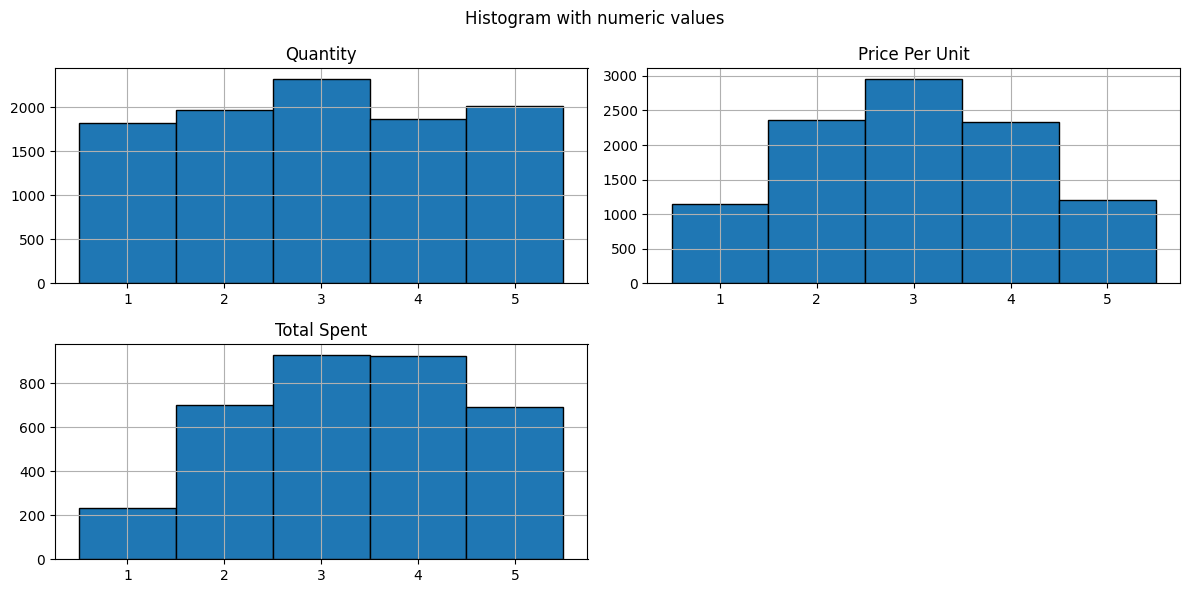

In [15]:
import matplotlib.pyplot as plt
custom_bins=[0.5,1.5,2.5,3.5,4.5,5.5]

df[["Quantity", "Price Per Unit", "Total Spent"]].hist(figsize=(12,6), bins=custom_bins,edgecolor='black',rwidth=1.0)
plt.suptitle("Histogram with numeric values")
plt.tight_layout()
plt.show()

In [16]:

from sklearn.preprocessing import StandardScaler

num_col = ["Quantity", "Price Per Unit", "Total Spent"]

scaler = StandardScaler()
df[num_col] = scaler.fit_transform(df[num_col])

df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,1,-0.741832,-0.765858,-0.832373,1,2,92
1,TXN_4977031,0,0.702686,0.038066,0.532746,0,1,184
2,TXN_4271903,2,0.702686,-1.569783,-0.149813,1,1,222
3,TXN_7034554,5,-0.741832,1.645914,0.191466,4,3,315
4,TXN_3160411,1,-0.741832,-0.765858,-0.832373,2,1,125


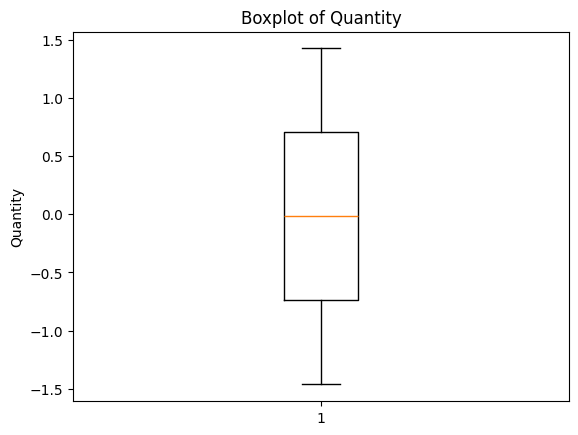

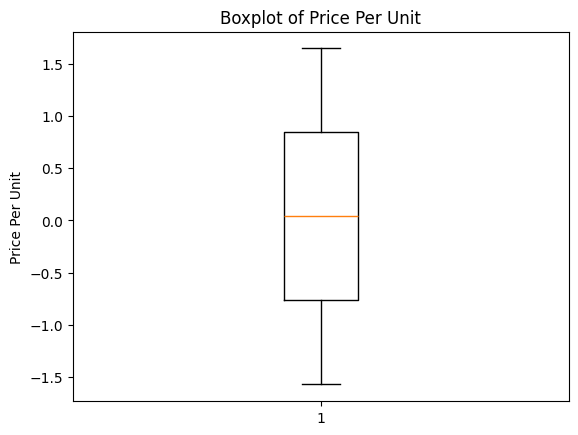

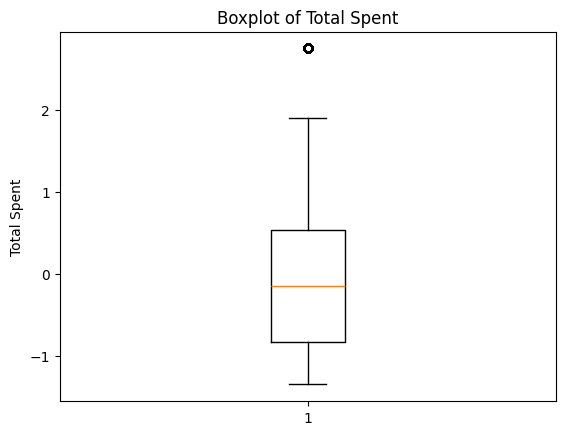

In [17]:
for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    plt.figure()
    plt.boxplot(df[col])
    plt.title("Boxplot of " + col)
    plt.ylabel(col)
    plt.show()

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              10000 non-null  int64  
 2   Quantity          10000 non-null  float64
 3   Price Per Unit    10000 non-null  float64
 4   Total Spent       10000 non-null  float64
 5   Payment Method    10000 non-null  int64  
 6   Location          10000 non-null  int64  
 7   Transaction Date  10000 non-null  int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 625.1+ KB


In [19]:
df.describe()

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000.000000,1.000000e+04,1.000000e+04,1.000000e+04,10000.0000,10000.000000,10000.000000
mean,4.224200,9.379164e-17,-1.385558e-16,-1.350031e-17,1.4103,1.660600,190.659800
std,2.727797,1.000050e+00,1.000050e+00,1.000050e+00,0.9647,0.602531,109.447639
min,0.000000,-1.464091e+00,-1.569783e+00,-1.344292e+00,0.0000,0.000000,0.000000
25%,2.000000,-7.418320e-01,-7.658584e-01,-8.323725e-01,1.0000,1.000000,94.750000
50%,4.000000,-1.957321e-02,3.806581e-02,-1.498132e-01,2.0000,2.000000,191.000000
75%,7.000000,7.026856e-01,8.419901e-01,5.327461e-01,2.0000,2.000000,286.000000
max,9.000000,1.424944e+00,1.645914e+00,2.751064e+00,4.0000,3.000000,366.000000


In [20]:

# Statistical Analysis

numerical_columns = ["Quantity", "Price Per Unit", "Total Spent"]

for column in numerical_columns:
    print("\n", column)
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Standard Deviation:", df[column].std())
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())

print("\nStatistical Summary:")
print(df[numerical_columns].describe())



 Quantity
Mean: 9.379164112033322e-17
Median: -0.019573213452067553
Standard Deviation: 1.0000500037503404
Minimum: -1.4640908113906375
Maximum: 1.4249443844865024

 Price Per Unit
Mean: -1.3855583347321954e-16
Median: 0.03806581297652653
Standard Deviation: 1.0000500037502882
Minimum: -1.5697826760003142
Maximum: 1.6459143019533673

 Total Spent
Mean: -1.3500311979441904e-17
Median: -0.14981323083707734
Standard Deviation: 1.0000500037503537
Minimum: -1.344291977758361
Maximum: 2.751063725971755

Statistical Summary:
           Quantity  Price Per Unit   Total Spent
count  1.000000e+04    1.000000e+04  1.000000e+04
mean   9.379164e-17   -1.385558e-16 -1.350031e-17
std    1.000050e+00    1.000050e+00  1.000050e+00
min   -1.464091e+00   -1.569783e+00 -1.344292e+00
25%   -7.418320e-01   -7.658584e-01 -8.323725e-01
50%   -1.957321e-02    3.806581e-02 -1.498132e-01
75%    7.026856e-01    8.419901e-01  5.327461e-01
max    1.424944e+00    1.645914e+00  2.751064e+00


In [21]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,1,-0.741832,-0.765858,-0.832373,1,2,92
1,TXN_4977031,0,0.702686,0.038066,0.532746,0,1,184
2,TXN_4271903,2,0.702686,-1.569783,-0.149813,1,1,222
3,TXN_7034554,5,-0.741832,1.645914,0.191466,4,3,315
4,TXN_3160411,1,-0.741832,-0.765858,-0.832373,2,1,125
